# HAB model evaluation

This notebook trains a small logistic-regression model on the labeled environmental feature dataset and evaluates **out-of-fold predictions**. It reports Precision, Recall, F1-score, and PR-AUC for every validation fold, then plots the fold-by-fold Precision-Recall curves.

The notebook is self-contained so it does not depend on importing `scripts/evaluate_predictions.py`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    precision_recall_curve,
    precision_score,
    recall_score,
)
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

plt.style.use('seaborn-v0_8-whitegrid')

## Load labeled model data

`target=1` is an observed HAB event and `target=0` is a synthetic non-event. The model uses the available numeric ocean/environmental features.

In [2]:
relative_data_path = Path('data/processed/hab_events_with_environmental_features.csv')
parent_data_path = Path('../data/processed/hab_events_with_environmental_features.csv')
data_path = relative_data_path if relative_data_path.exists() else parent_data_path
if not data_path.exists():
    raise FileNotFoundError('Could not find the labeled HAB feature dataset.')

data = pd.read_csv(data_path)
feature_columns = [
    'latitude', 'longitude', 'date_difference_hours', 'area_buffer_degrees',
    'surface_depth_m', 'thetao_valid_cells', 'so_valid_cells',
    'thetao_mean', 'thetao_p95', 'thetao_variance',
    'so_mean', 'so_p95', 'so_variance',
]
data = data.dropna(subset=feature_columns + ['target']).copy()
X = data[feature_columns]
y = data['target'].astype(int)

print(f'Dataset: {data_path}')
print(f'Rows used: {len(data)}')
print('Target counts:')
display(y.value_counts().sort_index().rename(index={0: 'Synthetic non-event', 1: 'HAB event'}).to_frame('count'))

Dataset: data\processed\hab_events_with_environmental_features.csv
Rows used: 194
Target counts:


,count
target,
Synthetic non-event,97
HAB event,97


## Generate fold predictions and calculate metrics

Each score below is produced on a validation row that was not used to fit that fold's model. `y_score` is the predicted probability of an HAB event, while the classification metrics use a probability threshold of 0.5.

In [3]:
n_splits = 5
threshold = 0.5
cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
fold_rows = []

for fold_number, (train_index, validation_index) in enumerate(cv.split(X, y), start=1):
    model = make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000, class_weight='balanced'),
    )
    model.fit(X.iloc[train_index], y.iloc[train_index])
    y_true = y.iloc[validation_index].to_numpy()
    y_score = model.predict_proba(X.iloc[validation_index])[:, 1]
    y_pred = (y_score >= threshold).astype(int)
    fold_rows.append(pd.DataFrame({
        'fold': fold_number,
        'y_true': y_true,
        'y_score': y_score,
        'y_pred': y_pred,
    }))

predictions = pd.concat(fold_rows, ignore_index=True)
metrics_rows = []
curves = {}
for fold, group in predictions.groupby('fold', sort=True):
    precision = precision_score(group['y_true'], group['y_pred'], zero_division=0)
    recall = recall_score(group['y_true'], group['y_pred'], zero_division=0)
    f1 = (2 * precision * recall / (precision + recall)) if precision + recall else 0.0
    pr_auc = average_precision_score(group['y_true'], group['y_score'])
    curve_precision, curve_recall, _ = precision_recall_curve(group['y_true'], group['y_score'])
    curves[fold] = (curve_recall, curve_precision, pr_auc)
    metrics_rows.append({
        'fold': fold,
        'precision': precision,
        'recall': recall,
        'f1_score': f1,
        'pr_auc': pr_auc,
        'samples': len(group),
    })

metrics = pd.DataFrame(metrics_rows)
metrics.loc[len(metrics)] = {
    'fold': 'mean',
    'precision': metrics['precision'].mean(),
    'recall': metrics['recall'].mean(),
    'f1_score': metrics['f1_score'].mean(),
    'pr_auc': metrics['pr_auc'].mean(),
    'samples': metrics['samples'].sum(),
}
display(metrics.round({'precision': 3, 'recall': 3, 'f1_score': 3, 'pr_auc': 3}))

,fold,precision,recall,f1_score,pr_auc,samples
0,1,0.348,0.421,0.381,0.377,39
1,2,0.286,0.211,0.242,0.530,39
2,3,0.333,0.300,0.316,0.384,39
3,4,0.214,0.150,0.176,0.399,39
4,5,0.300,0.158,0.207,0.405,38
5,mean,0.296,0.248,0.265,0.419,194


## Fold-by-fold Precision-Recall curves

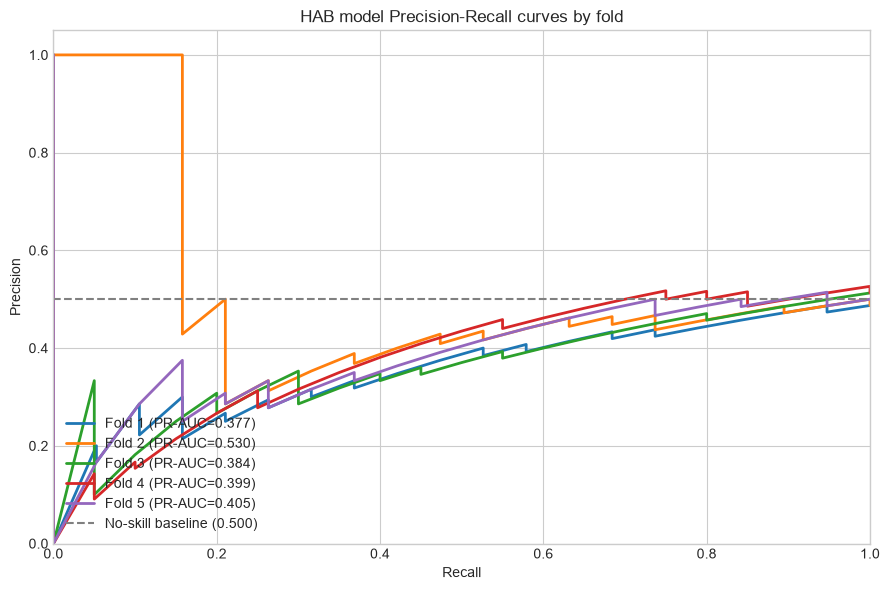

Saved results to: C:\Users\syng8\Documents\Oregon-State-University-1A-forecasting-risk-of-harmful-algal-blooms-in-coastal-marine-ecosystems\results


In [4]:
fig, ax = plt.subplots(figsize=(9, 6))
for fold, (recall_values, precision_values, pr_auc) in curves.items():
    ax.plot(recall_values, precision_values, linewidth=2, label=f'Fold {fold} (PR-AUC={pr_auc:.3f})')

positive_rate = y.mean()
ax.axhline(positive_rate, color='gray', linestyle='--', label=f'No-skill baseline ({positive_rate:.3f})')
ax.set_title('HAB model Precision-Recall curves by fold')
ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.05)
ax.legend(loc='lower left')
fig.tight_layout()
plt.show()

results_dir = Path('results') if Path('results').exists() or Path.cwd().name != 'notebooks' else Path('../results')
results_dir.mkdir(exist_ok=True)
fig.savefig(results_dir / 'hab_precision_recall_curves.png', dpi=150, bbox_inches='tight')
metrics.to_csv(results_dir / 'hab_fold_metrics.csv', index=False)
predictions.to_csv(results_dir / 'hab_oof_predictions.csv', index=False)
print(f'Saved results to: {results_dir.resolve()}')

## Inspect the actual out-of-fold predictions

These are the model probabilities and thresholded predictions used to calculate the metrics above.

In [5]:
display(predictions.head(15).round({'y_score': 3}))

,fold,y_true,y_score,y_pred
0,1,0,0.585,1
1,1,0,0.557,1
2,1,0,0.531,1
3,1,0,0.649,1
4,1,0,0.490,0
5,1,0,0.396,0
6,1,0,0.540,1
7,1,0,0.572,1
8,1,0,0.546,1
9,1,0,0.375,0
